# Assignment 2
## Exploratory Data Analysis (EDA) Using Python
### Programming for AI
### Palmer Penguins Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
%pip install pandas numpy matplotlib seaborn

  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl (72 kB)
Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl (7.3 MB)
U


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"

df = pd.read_csv(url)

df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [3]:
df.to_csv("penguins.csv", index=False)

In [4]:
df.shape

(344, 8)

In [5]:
df.columns

Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'year'],
      dtype='str')

In [6]:
df.dtypes

species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


In [8]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [9]:
df.describe(include='object')

C:\Users\user\AppData\Local\Temp\ipykernel_4672\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,male
freq,152,168,168


### Interpretation

The Palmer Penguins dataset contains information about different penguin species, their physical measurements, sex, and island. The dataset includes both numerical and categorical features. Descriptive statistics help us understand the distribution of numerical values and the frequency of categorical values.

In [10]:
df.isnull().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

In [11]:
df.isnull().sum().sum()

np.int64(19)

In [12]:
(df.isnull().sum().sum() / df.size) * 100

np.float64(0.690406976744186)

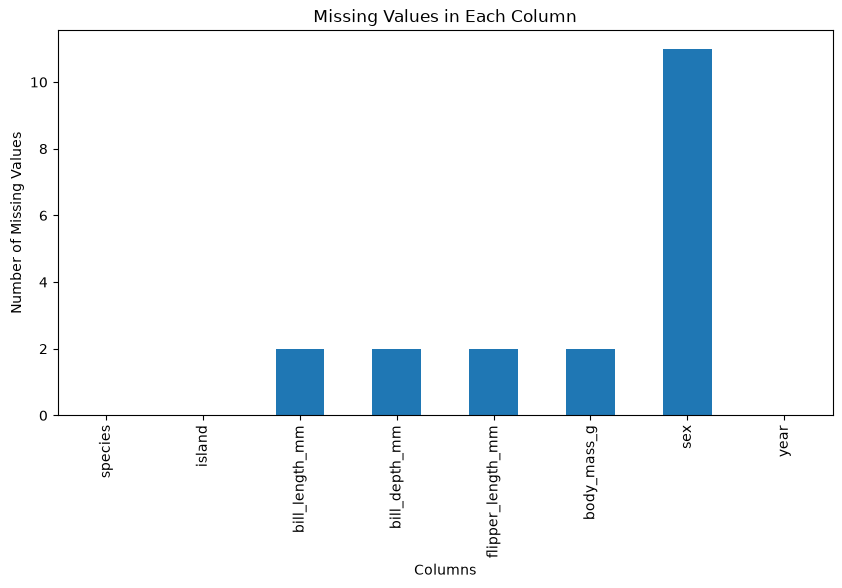

In [13]:
plt.figure(figsize=(10, 5))

df.isnull().sum().plot(kind='bar')

plt.title("Missing Values in Each Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")

plt.show()

In [14]:
df.select_dtypes(include=np.number).columns

Index(['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g',
       'year'],
      dtype='str')

In [15]:
df_clean = df.copy()

num_cols = df_clean.select_dtypes(include=np.number).columns

df_clean[num_cols] = df_clean[num_cols].fillna(
    df_clean[num_cols].median()
)

In [16]:
cat_cols = df_clean.select_dtypes(include='object').columns

for col in cat_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].mode()[0]
    )

C:\Users\user\AppData\Local\Temp\ipykernel_4672\4261178116.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_clean.select_dtypes(include='object').columns


In [17]:
df_clean.isnull().sum()

species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
year                 0
dtype: int64

### Interpretation

Missing numerical values were filled using the median because it is less affected by extreme values. Missing categorical values were filled using the mode because it represents the most frequent category. This helps preserve the dataset instead of deleting useful records.

In [18]:
df_clean.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
339    False
340    False
341    False
342    False
343    False
Length: 344, dtype: bool

In [19]:
df_clean.duplicated().sum()

np.int64(0)

In [20]:
df_clean = df_clean.drop_duplicates()

In [21]:
df_clean.duplicated().sum()

np.int64(0)

In [22]:
print("Rows before removing duplicates:", df.shape[0])
print("Rows after removing duplicates:", df_clean.shape[0])

Rows before removing duplicates: 344
Rows after removing duplicates: 344


### Interpretation

Duplicate records were identified using duplicated() and removed using drop_duplicates(). After removing duplicates, the dataset was checked again to verify that no duplicate rows remained. Removing duplicate records helps prevent repeated observations from affecting analysis.

In [23]:
cat_cols

Index(['species', 'island', 'sex'], dtype='str')

In [24]:
for col in cat_cols:
    print("\nColumn:", col)
    print(df_clean[col].unique())


Column: species
<StringArray>
['Adelie', 'Gentoo', 'Chinstrap']
Length: 3, dtype: str

Column: island
<StringArray>
['Torgersen', 'Biscoe', 'Dream']
Length: 3, dtype: str

Column: sex
<StringArray>
['male', 'female']
Length: 2, dtype: str


In [25]:
for col in cat_cols:
    print("\nColumn:", col)
    print(df_clean[col].value_counts())


Column: species
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Column: island
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

Column: sex
sex
male      179
female    165
Name: count, dtype: int64


In [26]:
for col in cat_cols:
    df_clean[col] = df_clean[col].str.strip().str.title()

In [27]:
for col in cat_cols:
    print("\nColumn:", col)
    print(df_clean[col].unique())


Column: species
<StringArray>
['Adelie', 'Gentoo', 'Chinstrap']
Length: 3, dtype: str

Column: island
<StringArray>
['Torgersen', 'Biscoe', 'Dream']
Length: 3, dtype: str

Column: sex
<StringArray>
['Male', 'Female']
Length: 2, dtype: str


### Interpretation

Categorical columns were examined for inconsistent formatting, extra spaces, and capitalization. String values were standardized using strip() and title() to maintain consistent category names. This improves data quality and avoids treating the same category as different values.

In [28]:
outlier_cols = ['bill_length_mm', 'flipper_length_mm']

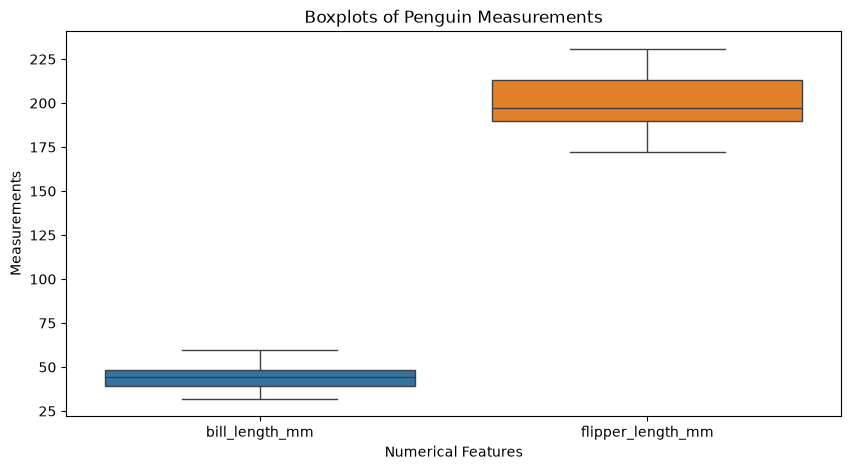

In [29]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df_clean[outlier_cols])

plt.title("Boxplots of Penguin Measurements")
plt.xlabel("Numerical Features")
plt.ylabel("Measurements")

plt.show()

In [30]:
for col in outlier_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    print("\nColumn:", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)


Column: bill_length_mm
Q1: 39.275
Q3: 48.5
IQR: 9.225000000000001
Lower Bound: 25.437499999999996
Upper Bound: 62.337500000000006

Column: flipper_length_mm
Q1: 190.0
Q3: 213.0
IQR: 23.0
Lower Bound: 155.5
Upper Bound: 247.5


In [31]:
for col in outlier_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    print("\nOutliers in", col)
    print(outliers[[col]])
    print("Total Outliers:", len(outliers))


Outliers in bill_length_mm
Empty DataFrame
Columns: [bill_length_mm]
Index: []
Total Outliers: 0

Outliers in flipper_length_mm
Empty DataFrame
Columns: [flipper_length_mm]
Index: []
Total Outliers: 0


### Interpretation

Boxplots and the IQR method were used to identify potential outliers in bill length and flipper length. Some extreme values may represent genuine biological variation rather than errors. Therefore, potential outliers were retained unless they were confirmed to be incorrect.

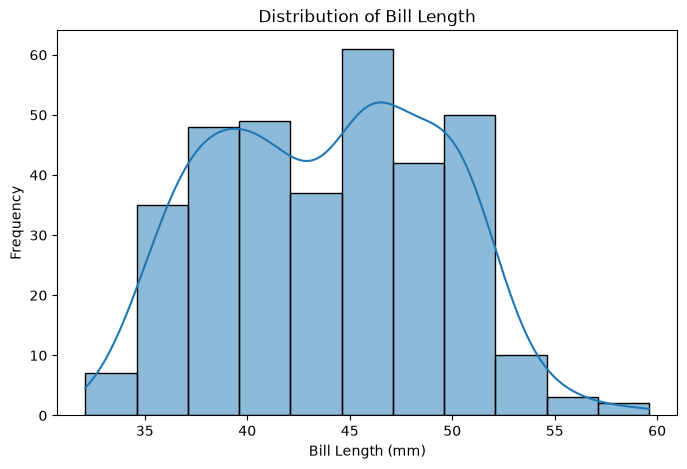

In [32]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df_clean, x='bill_length_mm', kde=True)

plt.title("Distribution of Bill Length")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Frequency")

plt.show()

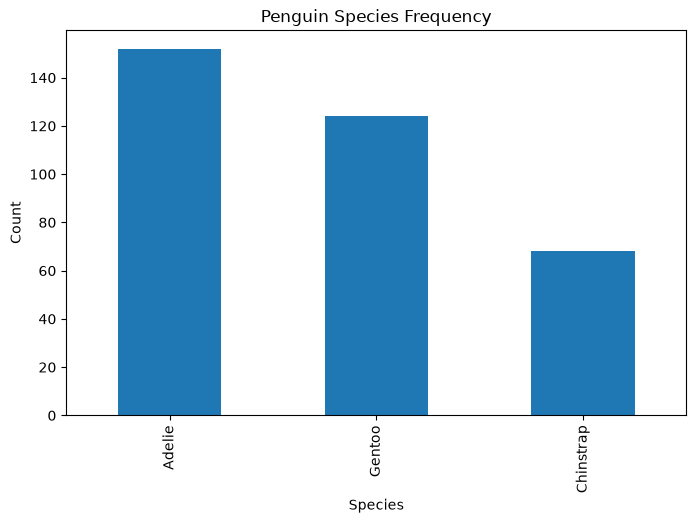

In [33]:
plt.figure(figsize=(8, 5))

df_clean['species'].value_counts().plot(kind='bar')

plt.title("Penguin Species Frequency")
plt.xlabel("Species")
plt.ylabel("Count")

plt.show()

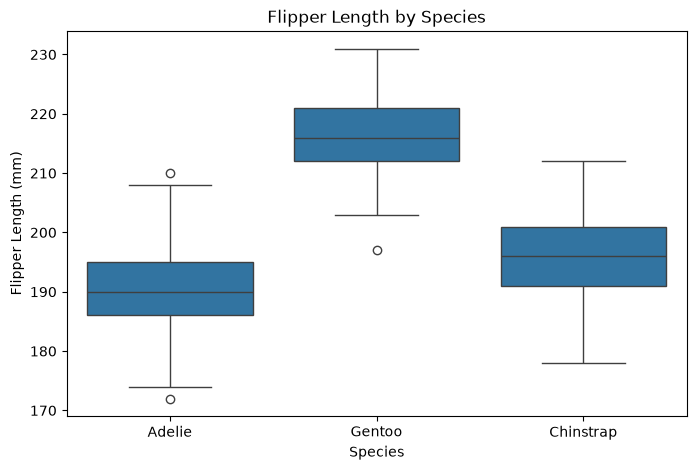

In [34]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x='species', y='flipper_length_mm')

plt.title("Flipper Length by Species")
plt.xlabel("Species")
plt.ylabel("Flipper Length (mm)")

plt.show()

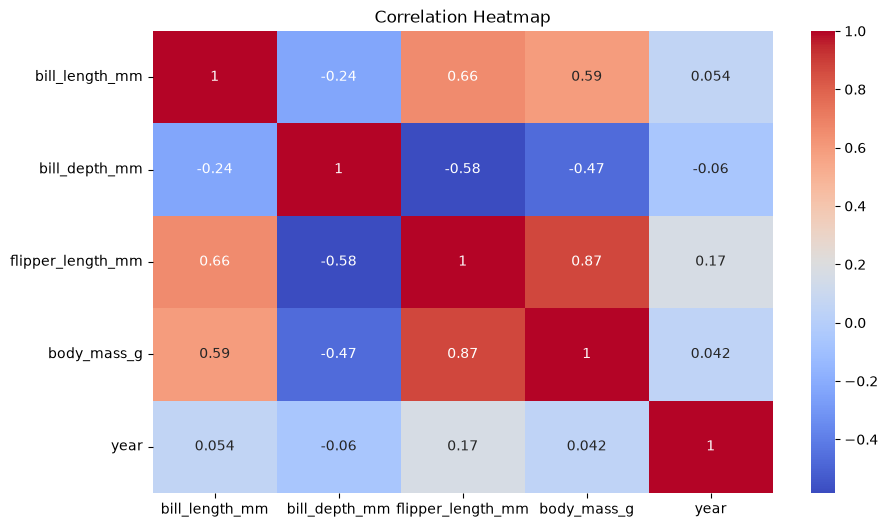

In [35]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df_clean.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()

In [36]:
df_clean['bill_ratio'] = (
    df_clean['bill_length_mm'] /
    df_clean['bill_depth_mm']
)

In [37]:
df_clean[['bill_length_mm', 'bill_depth_mm', 'bill_ratio']].head()

,bill_length_mm,bill_depth_mm,bill_ratio
0,39.10,18.7,2.090909
1,39.50,17.4,2.270115
2,40.30,18.0,2.238889
3,44.45,17.3,2.569364
4,36.70,19.3,1.901554


In [41]:
from sklearn.preprocessing import LabelEncoder

df_clean['species_label'] = LabelEncoder().fit_transform(
    df_clean['species']
)

df_clean[['species', 'species_label']].head()

,species,species_label
0,Adelie,0
1,Adelie,0
2,Adelie,0
3,Adelie,0
4,Adelie,0


In [39]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl (8.4 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl (37.4 MB)
Using cached threadpoolctl-3.8.0-py3-none-any.whl (32 kB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ -


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
from sklearn.preprocessing import LabelEncoder

In [42]:
df_encoded = pd.get_dummies(
    df_clean,
    columns=['island'],
    dtype=int
)

df_encoded.head()

,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,bill_ratio,species_label,island_Biscoe,island_Dream,island_Torgersen
0,Adelie,39.10,18.7,181.0,3750.0,Male,2007,2.090909,0,0,0,1
1,Adelie,39.50,17.4,186.0,3800.0,Female,2007,2.270115,0,0,0,1
2,Adelie,40.30,18.0,195.0,3250.0,Female,2007,2.238889,0,0,0,1
3,Adelie,44.45,17.3,197.0,4050.0,Male,2007,2.569364,0,0,0,1
4,Adelie,36.70,19.3,193.0,3450.0,Female,2007,1.901554,0,0,0,1


In [43]:
print("Before Encoding:")
print(df_clean[['island']].head())

print("\nAfter Encoding:")
print(df_encoded.filter(like='island_').head()
)

Before Encoding:
      island
0  Torgersen
1  Torgersen
2  Torgersen
3  Torgersen
4  Torgersen

After Encoding:
   island_Biscoe  island_Dream  island_Torgersen
0              0             0                 1
1              0             0                 1
2              0             0                 1
3              0             0                 1
4              0             0                 1


In [44]:
from sklearn.preprocessing import MinMaxScaler,StandardScaler

In [45]:
features = ['bill_length_mm', 'flipper_length_mm']

minmax = MinMaxScaler()

df_minmax = df_clean.copy()

df_minmax[features] = minmax.fit_transform(
    df_clean[features]
)

df_minmax[features].head()

,bill_length_mm,flipper_length_mm
0,0.254545,0.152542
1,0.269091,0.237288
2,0.298182,0.389831
3,0.449091,0.423729
4,0.167273,0.355932


In [46]:
standard = StandardScaler()

df_standard = df_clean.copy()

df_standard[features] = standard.fit_transform(
    df_clean[features]
)

df_standard[features].head()

,bill_length_mm,flipper_length_mm
0,-0.887622,-1.420541
1,-0.814037,-1.063485
2,-0.666866,-0.420786
3,0.096581,-0.277964
4,-1.329133,-0.563608


In [47]:
comparison = pd.DataFrame({
    'Original': df_clean['bill_length_mm'],
    'MinMax': df_minmax['bill_length_mm'],
    'Standardized': df_standard['bill_length_mm']
})

comparison.head()

,Original,MinMax,Standardized
0,39.10,0.254545,-0.887622
1,39.50,0.269091,-0.814037
2,40.30,0.298182,-0.666866
3,44.45,0.449091,0.096581
4,36.70,0.167273,-1.329133


In [48]:
df_clean.isnull().sum()

species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
year                 0
bill_ratio           0
species_label        0
dtype: int64

In [49]:
df_clean.duplicated().sum()

np.int64(0)

In [50]:
df_clean.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,bill_ratio,species_label
0,Adelie,Torgersen,39.10,18.7,181.0,3750.0,Male,2007,2.090909,0
1,Adelie,Torgersen,39.50,17.4,186.0,3800.0,Female,2007,2.270115,0
2,Adelie,Torgersen,40.30,18.0,195.0,3250.0,Female,2007,2.238889,0
3,Adelie,Torgersen,44.45,17.3,197.0,4050.0,Male,2007,2.569364,0
4,Adelie,Torgersen,36.70,19.3,193.0,3450.0,Female,2007,1.901554,0


In [51]:
df_clean.shape

(344, 10)

In [52]:
df_clean.to_csv("penguins_cleaned.csv", index=False)

In [53]:
pd.read_csv("penguins_cleaned.csv").head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,bill_ratio,species_label
0,Adelie,Torgersen,39.10,18.7,181.0,3750.0,Male,2007,2.090909,0
1,Adelie,Torgersen,39.50,17.4,186.0,3800.0,Female,2007,2.270115,0
2,Adelie,Torgersen,40.30,18.0,195.0,3250.0,Female,2007,2.238889,0
3,Adelie,Torgersen,44.45,17.3,197.0,4050.0,Male,2007,2.569364,0
4,Adelie,Torgersen,36.70,19.3,193.0,3450.0,Female,2007,1.901554,0


In [54]:
df_encoded = pd.get_dummies(
    df_clean,
    columns=['island']
)

df_encoded.head()

,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,bill_ratio,species_label,island_Biscoe,island_Dream,island_Torgersen
0,Adelie,39.10,18.7,181.0,3750.0,Male,2007,2.090909,0,False,False,True
1,Adelie,39.50,17.4,186.0,3800.0,Female,2007,2.270115,0,False,False,True
2,Adelie,40.30,18.0,195.0,3250.0,Female,2007,2.238889,0,False,False,True
3,Adelie,44.45,17.3,197.0,4050.0,Male,2007,2.569364,0,False,False,True
4,Adelie,36.70,19.3,193.0,3450.0,Female,2007,1.901554,0,False,False,True


In [55]:
display(df_encoded)

,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,bill_ratio,species_label,island_Biscoe,island_Dream,island_Torgersen
0,Adelie,39.10,18.7,181.0,3750.0,Male,2007,2.090909,0,False,False,True
1,Adelie,39.50,17.4,186.0,3800.0,Female,2007,2.270115,0,False,False,True
2,Adelie,40.30,18.0,195.0,3250.0,Female,2007,2.238889,0,False,False,True
3,Adelie,44.45,17.3,197.0,4050.0,Male,2007,2.569364,0,False,False,True
4,Adelie,36.70,19.3,193.0,3450.0,Female,2007,1.901554,0,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...
339,Chinstrap,55.80,19.8,207.0,4000.0,Male,2009,2.818182,1,False,True,False
340,Chinstrap,43.50,18.1,202.0,3400.0,Female,2009,2.403315,1,False,True,False
341,Chinstrap,49.60,18.2,193.0,3775.0,Male,2009,2.725275,1,False,True,False
342,Chinstrap,50.80,19.0,210.0,4100.0,Male,2009,2.673684,1,False,True,False


In [56]:
df_encoded.to_csv("penguins_cleaned.csv", index=False)

In [57]:
pd.read_csv("penguins_cleaned.csv").head()

,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,bill_ratio,species_label,island_Biscoe,island_Dream,island_Torgersen
0,Adelie,39.10,18.7,181.0,3750.0,Male,2007,2.090909,0,False,False,True
1,Adelie,39.50,17.4,186.0,3800.0,Female,2007,2.270115,0,False,False,True
2,Adelie,40.30,18.0,195.0,3250.0,Female,2007,2.238889,0,False,False,True
3,Adelie,44.45,17.3,197.0,4050.0,Male,2007,2.569364,0,False,False,True
4,Adelie,36.70,19.3,193.0,3450.0,Female,2007,1.901554,0,False,False,True


In [58]:
display(df_encoded)

,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,bill_ratio,species_label,island_Biscoe,island_Dream,island_Torgersen
0,Adelie,39.10,18.7,181.0,3750.0,Male,2007,2.090909,0,False,False,True
1,Adelie,39.50,17.4,186.0,3800.0,Female,2007,2.270115,0,False,False,True
2,Adelie,40.30,18.0,195.0,3250.0,Female,2007,2.238889,0,False,False,True
3,Adelie,44.45,17.3,197.0,4050.0,Male,2007,2.569364,0,False,False,True
4,Adelie,36.70,19.3,193.0,3450.0,Female,2007,1.901554,0,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...
339,Chinstrap,55.80,19.8,207.0,4000.0,Male,2009,2.818182,1,False,True,False
340,Chinstrap,43.50,18.1,202.0,3400.0,Female,2009,2.403315,1,False,True,False
341,Chinstrap,49.60,18.2,193.0,3775.0,Male,2009,2.725275,1,False,True,False
342,Chinstrap,50.80,19.0,210.0,4100.0,Male,2009,2.673684,1,False,True,False


In [ ]:
df_encoded.to_csv("penguins_cleaned.csv",index=False)